# Part 3 — Are the Profiles Real? Robustness and Alternative Methods
**Beyond Credit Scores: Discovering Borrower Risk Profiles and Early Warning Patterns for Loan Default**
DSAI 4102 Applied Data Mining · Group 1 · Lolwa Alboinin (60106354)

Part 2 found six borrower profiles with K-Means. Before anyone acts on them, this notebook tries to break them.

**The questions**
1. Do the profiles change if K-Means starts from a different random point?
2. Do they survive with one profile fewer or one more (K = 5, 7)?
3. Do the four "everyday" profiles still appear without the past-problem features?
4. Could a default-rate gap this large happen by chance?
5. What does a Gaussian Mixture Model find?
6. What does K-Prototypes find when it can also use the categorical features?
7. Which method should we trust?
8. Do the profiles still hold on loans from later years?

**Outputs:** `figures/03_*.png`, `data/processed/method_comparison.csv`

## Setup

In [15]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score
from kmodes.kprototypes import KPrototypes

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

K = 6  # Part 2's number of profiles
SEEDS = range(10)  # 10 different random starts for question 1
PERMUTATIONS = 1000  # label shuffles for question 4
# GMM is slow on 673k rows; 100k is plenty to estimate 6 components
GMM_SAMPLE = 100_000
# K-Prototypes is the slowest method, so every method is compared on the same 20k loans
SHARED_SAMPLE = 20_000

plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"

fs = json.loads((DATA_DIR / "feature_sets.json").read_text())
SEED = fs["random_state"]
FEATURES = fs["cluster_numeric"]
CATEGORICAL = fs["cluster_categorical"]

df = pd.read_parquet(DATA_DIR / fs["data_file"])
df = df.merge(pd.read_csv(DATA_DIR / "clusters_kmeans.csv"), on="id")
X = StandardScaler().fit_transform(df[FEATURES])  # same scaling as Part 2
base = df["profile"].to_numpy()  # Part 2's profiles: 1 = safest ... 6 = riskiest
y = df["default"].to_numpy()
print(f"{len(df):,} loans, {len(FEATURES)} features, Part 2 profiles loaded")

673,314 loans, 14 features, Part 2 profiles loaded


In [16]:
# Two measures used throughout:
# - risk spread: default rate of the riskiest group / the safest group (Part 2 found 1.87x)
# - ARI (adjusted Rand index): how similar two groupings are, from 1 (identical) to 0 (no better than chance).
#   It only looks at which loans end up together, so it doesn't matter that cluster numbers differ between runs.
def default_rates(labels, outcome=y):
    return pd.Series(outcome).groupby(np.asarray(labels)).mean()


def risk_spread(labels, outcome=y):
    rates = default_rates(labels, outcome)
    return rates.max() / rates.min()


def cramers_v(labels, outcome=y):
    chi2 = chi2_contingency(pd.crosstab(np.asarray(labels), np.asarray(outcome)))[0]
    # default is yes/no, so this is the full formula
    return np.sqrt(chi2 / len(outcome))


print(
    f"Part 2 profiles: risk spread {risk_spread(base):.2f}x, Cramer's V {cramers_v(base):.3f}"
)

Part 2 profiles: risk spread 1.87x, Cramer's V 0.092


## 1. Does the random starting point change the profiles?

ARI between seed pairs: mean 0.73, lowest 0.41
Part 2 model inertia: 6,537,800
      ARI vs Part 2     inertia
seed                           
0              0.97  6537919.85
1              0.98  6537865.98
2              0.51  6564586.27
3              0.51  6564588.12
4              0.96  6537926.28
5              0.98  6537872.30
6              0.98  6537885.57
7              0.97  6537918.56
8              0.97  6537895.59
9              0.41  6761013.34


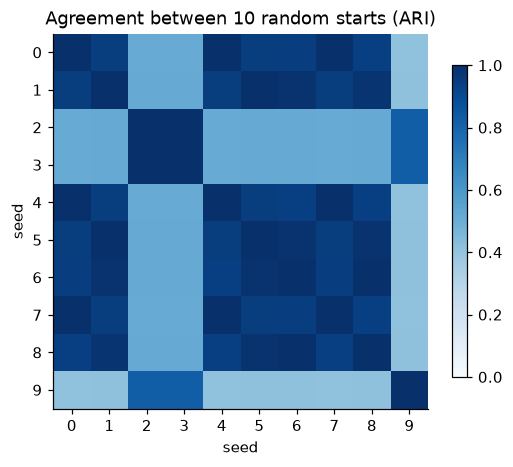

In [17]:
# K-Means starts from random centres. Each seed below is one single start (n_init=1),
# so if the profiles depended on luck, these 10 runs would disagree.
seed_fits = [KMeans(n_clusters=K, n_init=1, random_state=s).fit(X) for s in SEEDS]
seed_labels = [fit.labels_ for fit in seed_fits]

ari = np.array([[adjusted_rand_score(a, b) for b in seed_labels] for a in seed_labels])
pairs = ari[np.triu_indices(len(SEEDS), k=1)]
print(f"ARI between seed pairs: mean {pairs.mean():.2f}, lowest {pairs.min():.2f}")

# Inertia = total distance to the cluster centres (lower = a better fit). Part 2's model kept the best of
# 10 starts, so any seed that disagrees with it should also have a higher (worse) inertia.
part2_inertia = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X).inertia_
seed_table = pd.DataFrame(
    {
        "ARI vs Part 2": [adjusted_rand_score(base, labels) for labels in seed_labels],
        "inertia": [fit.inertia_ for fit in seed_fits],
    },
    index=pd.Index(SEEDS, name="seed"),
)
print(f"Part 2 model inertia: {part2_inertia:,.0f}")
print(seed_table.round(2).to_string())

fig, ax = plt.subplots(figsize=(5.5, 4.6))
im = ax.imshow(ari, cmap="Blues", vmin=0, vmax=1)
ax.set(
    title="Agreement between 10 random starts (ARI)",
    xlabel="seed",
    ylabel="seed",
    xticks=range(10),
    yticks=range(10),
)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIG_DIR / "03_seed_ari_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

**Answer: yes, as long as K-Means gets enough restarts.** 7 of the 10 single starts reproduce Part 2's profiles almost exactly (ARI 0.96–0.98 against Part 2). The other 3 (seeds 2, 3 and 9) land on different groupings (ARI 0.41–0.51), but every one of them has a higher inertia (6.56M–6.76M, against 6.54M for Part 2's model), so they are stuck in worse solutions. That is exactly why Part 2 runs 10 starts (`n_init=10`) and keeps the best one: the best solution is also the stable one.

## 2. Do the profiles survive with K = 5 or K = 7?

In [18]:
# Refit with one profile fewer and one more, then see where each Part 2 profile's borrowers end up.
# Clusters are renumbered by default rate (1 = safest), the same way Part 2 numbered its profiles.
def kmeans_by_risk(k, data=X):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(data)
    order = default_rates(labels).sort_values().index
    return (
        pd.Series(labels)
        .map({old: new for new, old in enumerate(order, start=1)})
        .to_numpy()
    )


labels_k = {k: kmeans_by_risk(k) for k in [5, 7]}
labels_k[6] = base

for k in [5, 7]:
    share = pd.crosstab(df["profile_name"], labels_k[k], normalize="index") * 100
    print(f"\nWhere each Part 2 profile goes at K = {k} (% of its borrowers):")
    print(share.round(0).to_string())


Where each Part 2 profile goes at K = 5 (% of its borrowers):
col_0                       1      2     3     4     5
profile_name                                          
Established homeowners   40.0   16.0  39.0   1.0   4.0
Heavy credit users        1.0    1.0  92.0   2.0   3.0
Public-record borrowers   0.0    0.0   0.0  99.0   0.0
Recent delinquents        0.0  100.0   0.0   0.0   0.0
Stretched borrowers       3.0    1.0   2.0   0.0  94.0
Thin-file starters       80.0    1.0   0.0   0.0  19.0

Where each Part 2 profile goes at K = 7 (% of its borrowers):
col_0                       1     2     3     4     5     6     7
profile_name                                                     
Established homeowners   49.0  45.0   0.0   0.0   0.0   1.0   6.0
Heavy credit users       12.0   1.0   0.0   0.0   0.0  85.0   2.0
Public-record borrowers   2.0   0.0   0.0   0.0  97.0   1.0   0.0
Recent delinquents        3.0   0.0   0.0  96.0   0.0   0.0   0.0
Stretched borrowers       0.0   4.0  1

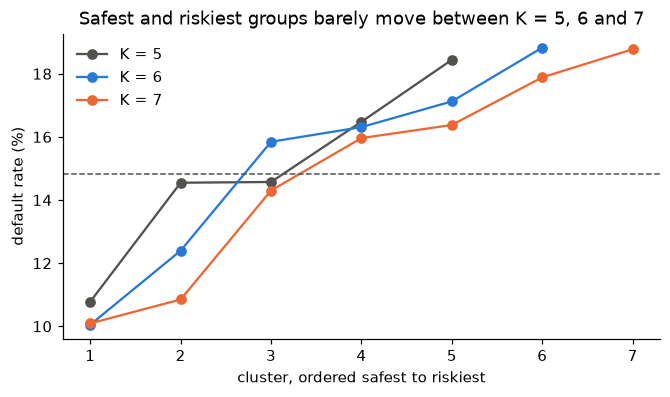

K = 5: safest 10.8%, riskiest 18.4%, spread 1.71x
K = 6: safest 10.0%, riskiest 18.8%, spread 1.87x
K = 7: safest 10.1%, riskiest 18.8%, spread 1.86x


In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, colour in zip([5, 6, 7], [GREY, BLUE, ORANGE]):
    rates = default_rates(labels_k[k]) * 100
    ax.plot(range(1, k + 1), rates.values, marker="o", color=colour, label=f"K = {k}")
ax.axhline(y.mean() * 100, color=GREY, linestyle="--", linewidth=1)
ax.set(
    title="Safest and riskiest groups barely move between K = 5, 6 and 7",
    xlabel="cluster, ordered safest to riskiest",
    ylabel="default rate (%)",
)
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "03_profiles_across_k.png", dpi=200, bbox_inches="tight")
plt.show()
for k in [5, 6, 7]:
    rates = default_rates(labels_k[k]) * 100
    print(
        f"K = {k}: safest {rates.iloc[0]:.1f}%, riskiest {rates.iloc[-1]:.1f}%, spread {risk_spread(labels_k[k]):.2f}x"
    )

**Answer: the risky end is stable; the safe end reshuffles.** Recent delinquents (96–100%), Public-record borrowers (97–99%), Heavy credit users (85–92%) and Stretched borrowers (76–94%) keep most of their borrowers at both K = 5 and K = 7. Established homeowners and Thin-file starters trade borrowers: at K = 5 the homeowners split across two clusters, and at K = 7 both of them split into new groups. The default rates at either end hardly move, though: the safest group sits at 10.0–10.8% and the riskiest at 18.4–18.8% for K = 5, 6 and 7. So the headline (the riskiest borrowers default at roughly 1.7–1.9x the safest) does not depend on the choice of K.

## 3. Without the past-problem features, do the other four profiles still appear?

In [20]:
# Profiles 3 (Recent delinquents) and 4 (Public-record borrowers) are each built around one past problem.
# Drop those three features, cluster again with K = 4, and check the other four profiles on their own loans.
PAST_PROBLEMS = ["delinq_2yrs", "has_delinq_history", "has_public_record"]
everyday = [f for f in FEATURES if f not in PAST_PROBLEMS]
X_everyday = StandardScaler().fit_transform(df[everyday])
labels_everyday = kmeans_by_risk(4, X_everyday)

other_four = ~np.isin(base, [3, 4])
share = (
    pd.crosstab(
        df.loc[other_four, "profile_name"],
        labels_everyday[other_four],
        normalize="index",
    )
    * 100
)
print(share.round(0).to_string())
print(
    f"\nARI on those loans: {adjusted_rand_score(base[other_four], labels_everyday[other_four]):.2f}"
)
print(
    "Default rate per new cluster (%):",
    (default_rates(labels_everyday) * 100).round(1).to_dict(),
)

col_0                      1     2     3     4
profile_name                                  
Established homeowners  85.0   8.0   2.0   5.0
Heavy credit users       3.0   0.0  96.0   0.0
Stretched borrowers      1.0   1.0   2.0  96.0
Thin-file starters       0.0  94.0   2.0   3.0

ARI on those loans: 0.82
Default rate per new cluster (%): {1: 10.2, 2: 12.5, 3: 17.8, 4: 19.0}


**Answer: yes.** With `delinq_2yrs`, `has_delinq_history` and `has_public_record` removed and K = 4, the four everyday profiles come back almost intact: 85% of Established homeowners, 94% of Thin-file starters, 96% of Heavy credit users and 96% of Stretched borrowers land together again (ARI 0.82 on their loans). Their default rates keep the same order (10.2%, 12.5%, 17.8%, 19.0%). Profiles 3 and 4 sit on top of the other four; the others don't depend on them.

## 4. Could a default-rate gap this large happen by chance?

Real spread 1.87x | shuffled: mean 1.021x, max 1.056x | p = 0.0010


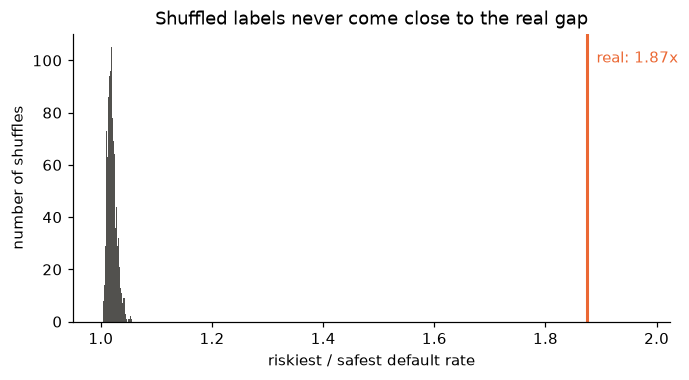

In [21]:
# Permutation test: shuffle the default labels, which breaks any real link with the profiles,
# and recompute the risk spread. Repeating it 1,000 times shows how big the spread gets by luck alone.
rng = np.random.default_rng(SEED)
real_spread = risk_spread(base)
shuffled = np.array(
    [risk_spread(base, rng.permutation(y)) for _ in range(PERMUTATIONS)]
)
p_value = (np.sum(shuffled >= real_spread) + 1) / (PERMUTATIONS + 1)
print(
    f"Real spread {real_spread:.2f}x | shuffled: mean {shuffled.mean():.3f}x, max {shuffled.max():.3f}x | p = {p_value:.4f}"
)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(shuffled, bins=30, color=GREY)
ax.axvline(real_spread, color=ORANGE, linewidth=2)
ax.text(
    real_spread, ax.get_ylim()[1] * 0.9, f"  real: {real_spread:.2f}x", color=ORANGE
)
ax.set(
    title="Shuffled labels never come close to the real gap",
    xlabel="riskiest / safest default rate",
    ylabel="number of shuffles",
    xlim=(0.95, real_spread * 1.08),
)
fig.savefig(FIG_DIR / "03_permutation_test.png", dpi=200, bbox_inches="tight")
plt.show()

**Answer: no.** Across 1,000 shuffles the spread averaged 1.02x and never went above 1.06x. The real 1.87x is far outside that range (p = 0.001, the smallest p-value 1,000 shuffles can give).

## 5. What does a Gaussian Mixture Model find?

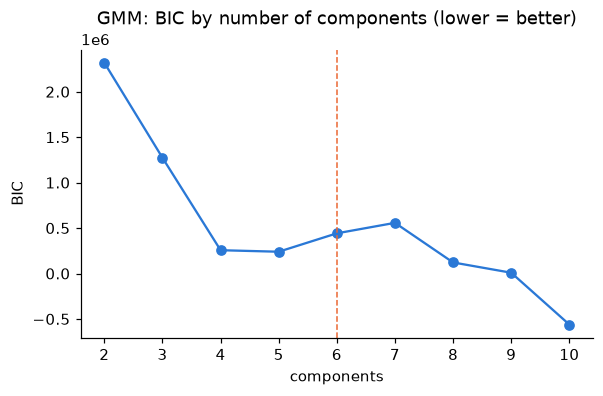

BIC: {2: 2318615, 3: 1273437, 4: 256295, 5: 239561, 6: 442012, 7: 557377, 8: 121659, 9: 8542, 10: -561548}


In [22]:
# A GMM treats each cluster as an oval-shaped cloud (any size, any tilt) rather than K-Means' round
# ones, and gives every borrower a probability of belonging to each cluster instead of one hard label.
# BIC picks the number of components: it rewards fit but charges for every extra parameter (lower = better).
gmm_rows = np.random.default_rng(SEED).choice(len(X), GMM_SAMPLE, replace=False)
bic = {
    k: GaussianMixture(n_components=k, covariance_type="full", random_state=SEED)
    .fit(X[gmm_rows])
    .bic(X[gmm_rows])
    for k in range(2, 11)
}

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(list(bic), list(bic.values()), marker="o", color=BLUE)
ax.axvline(K, color=ORANGE, linestyle="--", linewidth=1)
ax.set(
    title="GMM: BIC by number of components (lower = better)",
    xlabel="components",
    ylabel="BIC",
)
fig.savefig(FIG_DIR / "03_gmm_bic.png", dpi=200, bbox_inches="tight")
plt.show()
print("BIC:", {k: round(v) for k, v in bic.items()})

In [23]:
# Compare like with like: a 6-component GMM, then label every loan with its most likely component.
start = time.perf_counter()
gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=SEED).fit(
    X[gmm_rows]
)
gmm_labels = gmm.predict(X)
gmm_seconds = time.perf_counter() - start
print(
    f"GMM (6 components): risk spread {risk_spread(gmm_labels):.2f}x, ARI vs Part 2 {adjusted_rand_score(base, gmm_labels):.2f}"
)
summary = pd.DataFrame(
    {
        "share_%": pd.Series(gmm_labels).value_counts(normalize=True) * 100,
        "default_%": default_rates(gmm_labels) * 100,
    }
).sort_values("default_%")
summary["mostly Part 2 profile"] = pd.crosstab(gmm_labels, df["profile_name"]).idxmax(
    axis=1
)
summary.round(1)

GMM (6 components): risk spread 1.64x, ARI vs Part 2 0.19


,share_%,default_%,mostly Part 2 profile
5,39.0,12.3,Stretched borrowers
0,17.9,15.3,Recent delinquents
4,18.4,15.6,Thin-file starters
1,15.3,16.8,Public-record borrowers
3,4.6,18.7,Heavy credit users
2,4.7,20.3,Thin-file starters


**Answer: a weaker grouping, so not a better choice here.** BIC doesn't settle on a number of components: it falls until K = 5, rises again at 6–7, then keeps falling all the way to 10. That pattern usually means the full-covariance GMM is fitting very tight components around yes/no and count features such as `has_public_record` or `delinq_2yrs`, which BIC rewards, so BIC is not a reliable guide on this data. At 6 components, GMM separates risk less well than K-Means (1.64x vs 1.87x), largely disagrees with it (ARI 0.19), and puts 39% of all loans into a single component.

## 6. What does K-Prototypes find, using the categorical features too?

In [24]:
# K-Means can only use numbers. K-Prototypes measures distance on the numeric features as usual and
# counts mismatches on the categorical ones (home ownership, purpose, verification, term). gamma sets how
# much one categorical mismatch weighs against numeric distance; left empty, kmodes sets it from the data.
sample = np.random.default_rng(SEED).choice(len(X), SHARED_SAMPLE, replace=False)
mixed = np.column_stack([X[sample], df[CATEGORICAL].astype(str).to_numpy()[sample]])
cat_positions = list(range(len(FEATURES), len(FEATURES) + len(CATEGORICAL)))

start = time.perf_counter()
kproto = KPrototypes(n_clusters=K, init="Cao", n_init=3, random_state=SEED)
kproto_labels = kproto.fit_predict(mixed, categorical=cat_positions)
kproto_seconds = time.perf_counter() - start
print(f"gamma chosen by kmodes: {kproto.gamma:.2f} | {kproto_seconds:.0f}s")
print(
    f"risk spread {risk_spread(kproto_labels, y[sample]):.2f}x, ARI vs Part 2 {adjusted_rand_score(base[sample], kproto_labels):.2f}"
)

gamma chosen by kmodes: 0.50 | 35s
risk spread 1.82x, ARI vs Part 2 0.84


In [25]:
# A higher gamma makes the categories count more. If the clusters then just split by home ownership or
# purpose, the categorical features are taking over rather than adding information.
kproto_high = KPrototypes(
    n_clusters=K, init="Cao", n_init=3, gamma=kproto.gamma * 3, random_state=SEED
)
high_labels = kproto_high.fit_predict(mixed, categorical=cat_positions)
print(
    f"gamma x3 = {kproto.gamma * 3:.2f}: risk spread {risk_spread(high_labels, y[sample]):.2f}x, "
    f"ARI vs default-gamma run {adjusted_rand_score(kproto_labels, high_labels):.2f}"
)
print("\nHome ownership mix per cluster (gamma x3, %):")
print(
    (
        pd.crosstab(
            high_labels, df["home_ownership"].to_numpy()[sample], normalize="index"
        )
        * 100
    )
    .round(0)
    .to_string()
)

gamma x3 = 1.50: risk spread 1.79x, ARI vs default-gamma run 0.73

Home ownership mix per cluster (gamma x3, %):
col_0  MORTGAGE  OTHER   OWN  RENT
row_0                             
0          75.0    0.0   9.0  16.0
1          43.0    0.0  11.0  47.0
2          61.0    0.0  10.0  29.0
3          59.0    0.0  10.0  30.0
4          19.0    0.0   8.0  73.0
5          46.0    0.0  15.0  39.0


**Answer: almost the same profiles, so the categorical features don't change the picture.** With the gamma kmodes picks from the data (0.50), K-Prototypes reproduces K-Means' profiles closely (ARI 0.84 on the 20k sample) with nearly the same risk separation (1.82x). Tripling gamma to 1.50 makes the categories count more: the clusters start to line up with home ownership (one cluster is 75% mortgage holders, another 73% renters) and drift away from the default run (ARI 0.73), but risk separation doesn't improve (1.79x). So home ownership, purpose, verification and term add little that the numeric features don't already capture, and K-Prototypes took 35 seconds on a sample about 34 times smaller than the full data.

## 7. Which method should we trust?

In [26]:
# Every method scored on the same 20k loans, so the comparison is fair.
# Part 2's model was fitted in another notebook, so one identical K-Means fit is timed here
# for the fit-time column.
start = time.perf_counter()
KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
kmeans_seconds = time.perf_counter() - start

methods = {
    "K-Means (Part 2)": base[sample],
    "Gaussian Mixture": gmm_labels[sample],
    "K-Prototypes": kproto_labels,
}
seconds = {
    "K-Means (Part 2)": kmeans_seconds,
    "Gaussian Mixture": gmm_seconds,
    "K-Prototypes": kproto_seconds,
}
comparison = pd.DataFrame(
    {
        name: {
            "silhouette": silhouette_score(X[sample], labels),
            "ARI vs K-Means": adjusted_rand_score(base[sample], labels),
            "risk spread (x)": risk_spread(labels, y[sample]),
            "Cramer's V": cramers_v(labels, y[sample]),
            "fit time (s)": seconds[name],
        }
        for name, labels in methods.items()
    }
).T
comparison.round(3).to_csv(DATA_DIR / "method_comparison.csv")
comparison.round(3)
# fit time: K-Means and GMM on their full fitting data (673k and 100k loans), K-Prototypes on the 20k sample

,silhouette,ARI vs K-Means,risk spread (x),Cramer's V,fit time (s)
K-Means (Part 2),0.092,1.000,1.839,0.090,2.325
Gaussian Mixture,0.034,0.188,1.592,0.065,4.547
K-Prototypes,0.091,0.841,1.823,0.088,35.455


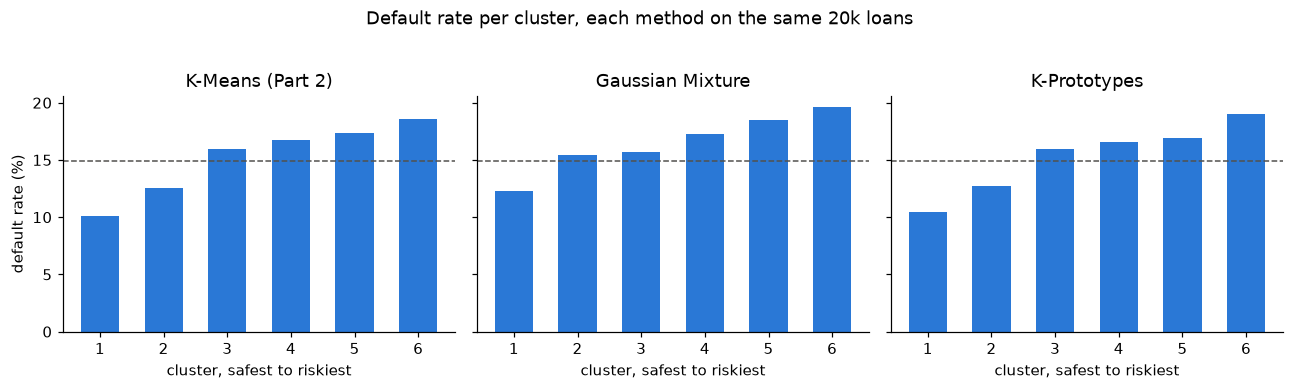

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (name, labels) in zip(axes, methods.items()):
    rates = default_rates(labels, y[sample]).sort_values() * 100
    ax.bar(range(1, K + 1), rates.values, color=BLUE, width=0.6)
    ax.axhline(y[sample].mean() * 100, color=GREY, linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="cluster, safest to riskiest")
axes[0].set_ylabel("default rate (%)")
fig.suptitle("Default rate per cluster, each method on the same 20k loans", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_method_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Answer: K-Means.** On the same 20k loans, K-Means and K-Prototypes are nearly tied (silhouette 0.092 vs 0.091, risk spread 1.84x vs 1.82x, Cramér's V 0.090 vs 0.088) and largely agree (ARI 0.84). The Gaussian Mixture is clearly weaker on every measure (silhouette 0.034, spread 1.59x, V 0.065) and finds a different structure (ARI 0.19). K-Means wins the tie-break: it's the simplest of the three, it runs on all 673k loans in a few seconds, and its profile centres are easy to read and explain to a lender. (K-Means' spread is 1.84x on this sample and 1.87x on all loans.)

## 8. Do the profiles still hold on loans from later years?

ARI vs Part 2 profiles: 0.52


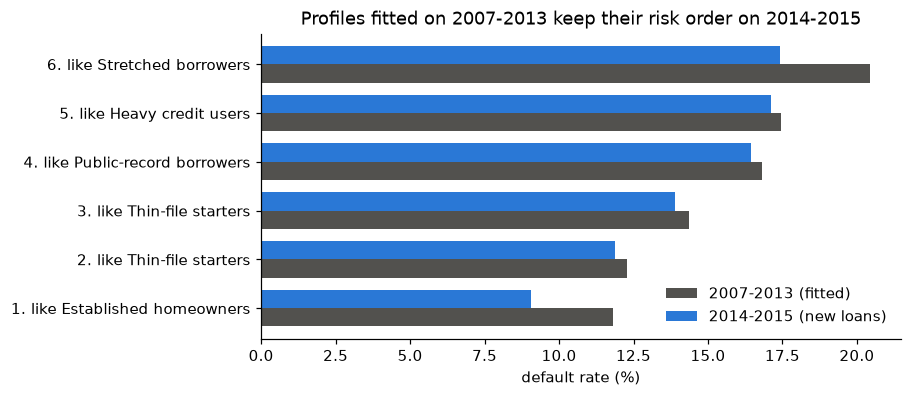

,2007-2013 (fitted),2014-2015 (new loans)
1. like Established homeowners,11.8,9.1
2. like Thin-file starters,12.3,11.9
3. like Thin-file starters,14.4,13.9
4. like Public-record borrowers,16.8,16.4
5. like Heavy credit users,17.5,17.1
6. like Stretched borrowers,20.4,17.4


In [28]:
# Fit K-Means only on loans issued up to 2013, then place every 2014-2015 loan in its nearest profile,
# the way a lender would profile new applicants. If the ranking of default rates holds, the profiles are usable.
# (2007-2011 loans have median-filled mort_acc and acc_open_past_24mths - see Part 1.)
early = (df["issue_year"] <= 2013).to_numpy()
km_early = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X[early])
time_labels = km_early.predict(X)
# closest Part 2 profile for each
names = pd.crosstab(time_labels, df["profile_name"]).idxmax(axis=1)

by_period = pd.DataFrame(
    {
        "2007-2013 (fitted)": default_rates(time_labels[early], y[early]) * 100,
        "2014-2015 (new loans)": default_rates(time_labels[~early], y[~early]) * 100,
    }
)
by_period = by_period.sort_values("2007-2013 (fitted)")
# label by risk order + closest Part 2 profile (two clusters can share the same closest profile)
by_period.index = [
    f"{rank}. like {names[c]}" for rank, c in enumerate(by_period.index, start=1)
]
print(f"ARI vs Part 2 profiles: {adjusted_rand_score(base, time_labels):.2f}")

ax = by_period.plot.barh(figsize=(7.5, 3.6), color=[GREY, BLUE], width=0.75)
ax.set(
    title="Profiles fitted on 2007-2013 keep their risk order on 2014-2015",
    xlabel="default rate (%)",
    ylabel="",
)
ax.legend(frameon=False, loc="lower right")
plt.savefig(FIG_DIR / "03_out_of_time.png", dpi=200, bbox_inches="tight")
plt.show()
by_period.round(1)

**Answer: yes, the risk order holds.** Fitted only on 2007–2013 loans, K-Means finds a slightly different set of six (ARI 0.52 against Part 2): Recent delinquents don't form their own group and Thin-file starters split in two, partly because the early loans have median-filled `mort_acc` and `acc_open_past_24mths`. But when the 2014–2015 loans are placed into these profiles, their default rates come out in exactly the same order, safest to riskiest, from 9.1% to 17.4% (a 1.91x spread on loans the model never saw). A lender could profile new applicants this way and still rank their risk correctly.

## Verdict
The six profiles are real, not an accident of the settings:
- **Stable across random starts** once K-Means keeps the best of 10 (Q1), and their risky end survives K = 5 and 7 (Q2).
- **Not built on the two past-problem features:** the four everyday profiles reappear without them (ARI 0.82, Q3).
- **Not chance:** shuffled labels never produce more than a 1.06x gap, against the real 1.87x (Q4).
- **Confirmed by a second method:** K-Prototypes, which also uses the categorical features, finds nearly the same profiles (ARI 0.84, Q6). The Gaussian Mixture is weaker on this data (Q5, Q7).
- **Usable on new applicants:** profiles fitted on 2007–2013 rank 2014–2015 loans in the same risk order (Q8).

**Limits:** the safe end of the ranking (Established homeowners vs Thin-file starters) is less stable than the risky end; BIC was not a reliable guide for the Gaussian Mixture here; and K-Prototypes ran on a 20k sample because of its run time.